## Exercise 12.4 (Regression of multivariate time series)  

- Load the AppliancesEnergy data set.
- Use the time series k nearest neighbour algorithm to predict the energy consumption of the appliances.
- Use the time series random forest tree algorithm to predict the energy consumption of the appliances.
- Use the CNN regressor to predict the energy consumption of the appliances.
- How do the results compare?

# 1 Load the AppliancesEnergy data set.

In [1]:
from aeon.datasets import load_regression

ds_name = "AppliancesEnergy"

# Trainings- und Testdaten getrennt laden.
X_train, y_train = load_regression(ds_name, split="train")
X_test, y_test = load_regression(ds_name, split="test")

print("Form der Trainingsdaten:", X_train.shape)
print("Form der Testdaten:", X_test.shape)
print("Erste Zielwerte:", y_train[:5])

Form der Trainingsdaten: (95, 24, 144)
Form der Testdaten: (42, 24, 144)
Erste Zielwerte: [19.38 12.68  5.34 12.72 13.25]


# 2 Use the time series k nearest neighbour algorithm to predict the energy consumption of the appliances.

RMSE auf den Testdaten: 4.4168
Laufzeit für Training und Vorhersage: 2.04 Sekunden.


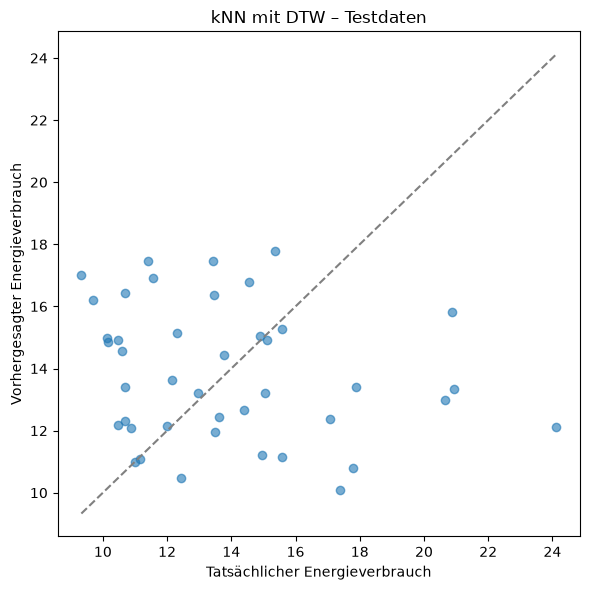

In [8]:
import time
import matplotlib.pyplot as plt
from sktime.regression.distance_based import KNeighborsTimeSeriesRegressor
from sklearn.metrics import root_mean_squared_error

# 1. kNN-Regressor mit DTW-Distanz erstellen.
knn_reg = KNeighborsTimeSeriesRegressor(
    n_neighbors=5,          # Anzahl der Nachbarn
    weights="distance",      # Gewichtung der Nachbarn
    distance="dtw"          # Distanzmaß: Dynamic Time Warping
)

# 2. Mit den Trainingszeitreihen und Verbrauchswerten trainieren.
start_time = time.time()

knn_reg.fit(X_train, y_train)

# 3. Energieverbrauch für die Testzeitreihen vorhersagen.
y_pred_knn = knn_reg.predict(X_test)

duration_knn = time.time() - start_time

# 4. Vorhersagefehler berechnen.
rmse_knn = root_mean_squared_error(y_test, y_pred_knn)

print(f"RMSE auf den Testdaten: {rmse_knn:.4f}")
print(f"Laufzeit für Training und Vorhersage: {duration_knn:.2f} Sekunden.")

# 5. Tatsächliche und vorhergesagte Werte vergleichen.
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(y_test, y_pred_knn, alpha=0.6)

# Auf der Diagonalen stimmen Vorhersage und tatsächlicher Wert überein.
lower = min(y_test.min(), y_pred_knn.min())
upper = max(y_test.max(), y_pred_knn.max())
ax.plot([lower, upper], [lower, upper], "--", color="grey")

ax.set_title("kNN mit DTW – Testdaten")
ax.set_xlabel("Tatsächlicher Energieverbrauch")
ax.set_ylabel("Vorhergesagter Energieverbrauch")

plt.tight_layout()
plt.show()

# 3 Use the time series random forest tree algorithm to predict the energy consumption of the appliances.

RMSE auf den Testdaten: 2.1117
Laufzeit für Training und Vorhersage: 8.87 Sekunden.


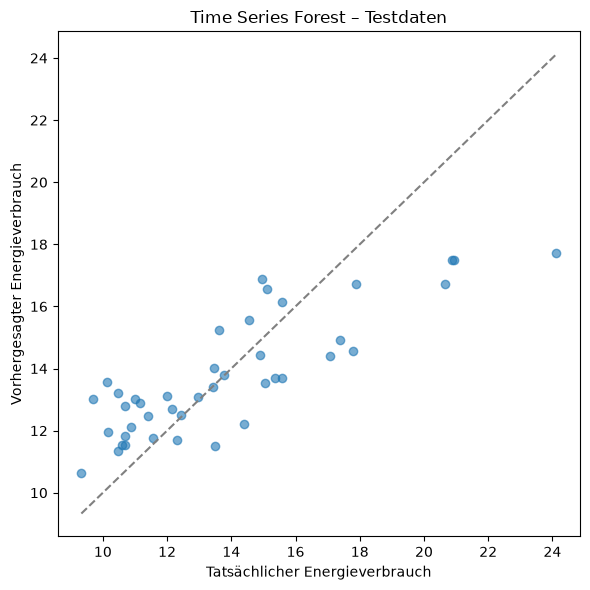

In [9]:
import time
import matplotlib.pyplot as plt
from aeon.regression.interval_based import TimeSeriesForestRegressor
from sklearn.metrics import root_mean_squared_error

# 1. Time Series Forest mit 200 Regressionsbäumen erstellen.
tsf_reg = TimeSeriesForestRegressor(
    n_estimators=200,
    random_state=42
)

# 2. Mit den Trainingszeitreihen und Verbrauchswerten trainieren.
start_time = time.time()

tsf_reg.fit(X_train, y_train)

# 3. Energieverbrauch für die Testzeitreihen vorhersagen.
y_pred_tsf = tsf_reg.predict(X_test)

duration_tsf = time.time() - start_time

# 4. Vorhersagefehler berechnen.
rmse_tsf = root_mean_squared_error(y_test, y_pred_tsf)

print(f"RMSE auf den Testdaten: {rmse_tsf:.4f}")
print(f"Laufzeit für Training und Vorhersage: {duration_tsf:.2f} Sekunden.")

# 5. Tatsächliche und vorhergesagte Werte vergleichen.
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(y_test, y_pred_tsf, alpha=0.6)

# Die Diagonale kennzeichnet perfekte Vorhersagen.
lower = min(y_test.min(), y_pred_tsf.min())
upper = max(y_test.max(), y_pred_tsf.max())
ax.plot([lower, upper], [lower, upper], "--", color="grey")

ax.set_title("Time Series Forest – Testdaten")
ax.set_xlabel("Tatsächlicher Energieverbrauch")
ax.set_ylabel("Vorhergesagter Energieverbrauch")

plt.tight_layout()
plt.show()

# 4 Use the CNN regressor to predict the energy consumption of the appliances.

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 144, 24)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 138, 6)         │         1,014 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling1d               │ (None, 46, 6)          │             0 │
│ (AveragePooling1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 40, 12)         │           516 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling1d_1             │ (None, 13, 12)         │             0 │
│ (AveragePooling1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 156)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           157 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,687 (6.59 KB)

 Trainable params: 1,687 (6.59 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.1059
Epoch 2/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0884
Epoch 3/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0778 
Epoch 4/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0686
Epoch 5/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0656
Epoch 6/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0600
Epoch 7/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.0536 
Epoch 8/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0509
Epoch 9/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0487
Epoch 10/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0451
Epoch 11/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0436 
Epoch 12/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0428
Epoch 13/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0406
Epoch 14/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0389
Epoch 15/80
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0379
Epoch 16/80
2/2 ━━━━━━━━━━━━━━━

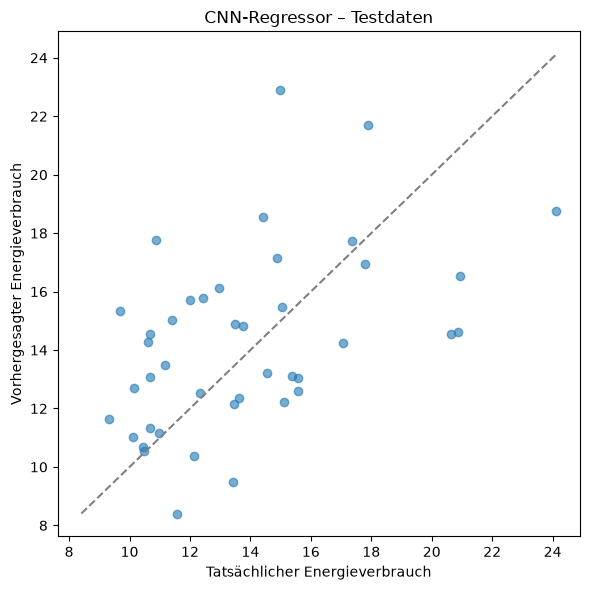

In [10]:
import time
import numpy as np
import matplotlib.pyplot as plt

from tslearn.preprocessing import TimeSeriesScalerMinMax
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import root_mean_squared_error
from sktime.regression.deep_learning.cnn import CNNRegressor
from tensorflow.keras.optimizers import Adam

# 1. Eingabedaten für die Skalierung umformen.
# tslearn erwartet: (Zeitreihen, Messpunkte, Messgrößen).
X_train_tslearn = np.transpose(X_train, (0, 2, 1))
X_test_tslearn = np.transpose(X_test, (0, 2, 1))

# Jede Messgröße innerhalb einer Zeitreihe auf [0, 1] skalieren.
scaler_x = TimeSeriesScalerMinMax()

X_train_scaled = scaler_x.fit_transform(X_train_tslearn)
X_test_scaled = scaler_x.transform(X_test_tslearn)

# Für sktime zurück zu: (Zeitreihen, Messgrößen, Messpunkte).
X_train_cnn = np.transpose(X_train_scaled, (0, 2, 1))
X_test_cnn = np.transpose(X_test_scaled, (0, 2, 1))

# 2. Zielwerte skalieren.
# Die Skalierung ausschließlich anhand der Trainingszielwerte bestimmen.
scaler_y = MinMaxScaler()
y_train_scaled = scaler_y.fit_transform(
    np.asarray(y_train).reshape(-1, 1)
).ravel()

# 3. CNN-Regressor konfigurieren.
cnn_reg = CNNRegressor(
    activation="linear",
    activation_hidden="leaky_relu",
    batch_size=64,
    metrics=[],
    n_conv_layers=2,
    n_epochs=80,
    optimizer=Adam(),
    random_state=42,
    verbose=True
)

# 4. Trainieren und Testwerte vorhersagen.
start_time = time.time()

cnn_reg.fit(X_train_cnn, y_train_scaled)
y_pred_scaled = cnn_reg.predict(X_test_cnn)

# Vorhersagen in die ursprüngliche Verbrauchsskala zurückführen.
y_pred_cnn = scaler_y.inverse_transform(
    np.asarray(y_pred_scaled).reshape(-1, 1)
).ravel()

duration_cnn = time.time() - start_time

# 5. Fehler in der ursprünglichen Skala berechnen.
rmse_cnn = root_mean_squared_error(y_test, y_pred_cnn)

print(f"RMSE auf den Testdaten: {rmse_cnn:.4f}")
print(f"Laufzeit für Training und Vorhersage: {duration_cnn:.2f} Sekunden.")

# 6. Tatsächliche und vorhergesagte Werte darstellen.
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(y_test, y_pred_cnn, alpha=0.6)

lower = min(y_test.min(), y_pred_cnn.min())
upper = max(y_test.max(), y_pred_cnn.max())
ax.plot([lower, upper], [lower, upper], "--", color="grey")

ax.set_title("CNN-Regressor – Testdaten")
ax.set_xlabel("Tatsächlicher Energieverbrauch")
ax.set_ylabel("Vorhergesagter Energieverbrauch")

plt.tight_layout()
plt.show()

# 5 How do the results compare?

| Verfahren | RMSE | Laufzeit für Training und Vorhersage |
|---|---:|---:|
| kNN mit DTW | 4,4168 | 2,04 s |
| Time Series Forest | 2,1117 | 8,87 s |
| CNN | 3,3766 | 9,68 s |

Der Time Series Forest liefert mit dem niedrigsten RMSE die besten Vorhersagen. Seine Punkte liegen im Diagramm insgesamt näher an der Diagonalen. kNN ist am schnellsten, überschätzt jedoch häufig niedrige Verbrauchswerte und unterschätzt hohe Werte.

Das CNN erzielt einen geringeren Fehler als kNN, zeigt aber weiterhin deutliche Abweichungen und benötigt die längste Laufzeit. Anders als die anderen Verfahren verwendet es skalierte Eingabedaten. Der Vergleich bewertet daher die jeweils gewählte Verarbeitung einschließlich des Modells.

Für diesen Datensatz und die verwendeten Einstellungen liefert der Time Series Forest das beste Ergebnis. Die Parameter wurden nicht systematisch optimiert; die Ergebnisse beziehen sich auf den vorgegebenen Testdatensatz und jeweils einen Durchlauf.

ipynb exportiert als html mit:

uv run jupyter nbconvert --to html "Tasks/12 Self study - Session 3/Exercise_12.4.ipynb"